<!-- d2l:prose id=memory-precision-md-1 fw=all -->

# Memory and Precision

The previous sections asked how fast a training step runs; a step that does not
fit in GPU memory does not run at all. Our 1B-parameter GPT trained with Adam
in fp32 stores four fp32 values per parameter—the weight, its gradient, and
Adam's two moment estimates—consuming $16N \approx 15.1$ GiB of a 24 GiB
RTX 4090 before reading a single token. The remaining ~9 GiB must hold the
*activations* saved by the forward pass for backpropagation, which take
several megabytes per token. As a result, only two or three sequences of 1,024
tokens fit on the card, whereas large language models train on global batches
of half a million to several million tokens [@brown2020language].

The memory of a training step consists of a fixed parameter term proportional
to $N$ and an activation term proportional to the number of tokens $n$. In
this section we count both for our GPT, verify the count against measured peak
memory, and study three techniques that act on the activation term or the
micro-batch size: *mixed precision* (computing in 16 bits), *activation
checkpointing* (recomputing activations during the backward pass instead of
storing them), and *gradient accumulation* (splitting a large global batch
into sequential micro-batches). None of the three shrinks the $16N$ bytes of
parameter state; dividing that state across GPUs is the subject of
that section.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
import os
import re
from torch.utils.checkpoint import checkpoint
# Detach PyTorch's profiler from the GPU when a profile ends; without this,
# every kernel launch after the first profile stays about 30% slower
os.environ['TEARDOWN_CUPTI'] = '1'

<!-- d2l:prose id=memory-precision-md-2 fw=all -->

## Memory of a Training Step

### Memory per Parameter

Parameter memory depends on the optimizer: plain fp32 SGD stores a weight and
gradient (8 bytes/parameter), SGD with momentum adds a velocity (12 bytes),
and Adam stores two moment estimates (**16 bytes/parameter**,
that section). Mixed-precision training keeps all
four in fp32 and holds a 16-bit weight copy during the step (**18
bytes/parameter**).

Our reference model is `d2l.GPT` (that section) with width $d = 2048$, 16
heads, $L = 18$ pre-norm SwiGLU blocks, vocabulary $V = 50{,}257$, and learned
positional embeddings. Each block holds ~$12d^2 \approx 50$M parameters
(~0.9B across 18 blocks, plus ~0.1B in the tied token embedding). Inspecting
the model on a meta/shape-only device confirms $N$ without allocating 4 GB of
weights (that section):

In [3]:
config = dict(vocab_size=50257, num_hiddens=2048, num_heads=16,
              num_blks=18, pos='learned')
with torch.device('meta'):  # Shapes and dtypes only, no data
    model = d2l.GPT(**config)
N = d2l.num_params(model)
print(f'{N / 1e9:.2f} billion parameters, 16N = {16 * N / 2**30:.1f} GiB')

1.01 billion parameters, 16N = 15.1 GiB


<!-- d2l:prose id=memory-precision-md-3 fw=all -->

### Memory per Token

During the forward pass, layers save intermediate activations needed by the
backward pass; during the backward pass, these activations are freed layer by
layer as parameter gradients are produced (the figure).
Memory therefore peaks at the start of the backward pass.

![The memory of a training step with Adam, in units of $4N$ bytes. The
weights ($4N$) and Adam's moment estimates ($8N$) stay for the whole step.
Activations accumulate during the forward pass and are released during the
backward pass, while the gradients ($4N$) appear. Memory peaks at the start
of the backward pass.](../img/mdl-perf-memory-anatomy.svg)

Three rules determine what a Transformer block saves for backpropagation:

1. A linear layer $\mathbf{y} = \mathbf{W}\mathbf{x}$ saves its input
   $\mathbf{x}$ (since $\nabla_{\mathbf{W}} = (\nabla_{\mathbf{y}})\mathbf{x}^\top$).
2. An elementwise nonlinearity $f$ saves its input or output.
3. An elementwise product $\mathbf{p} \odot \mathbf{q}$ saves both factors.

Counting per token in units of width $d = 2048$:

* **Attention sublayer:** Pre-attention RMSNorm saves its input ($d$); the QKV
  projection saves the normalized output ($d$); fused causal attention saves
  $\mathbf{Q}, \mathbf{K}, \mathbf{V}$ ($3d$) and its output ($d$, plus only a
  scalar log-normalizer per head and token instead of the $T \times T$ score
  matrix); the output projection saves the attention output ($0$ if aliased, or
  $d$ if copied when merging heads). Total: $6d\text{--}7d$.
* **SwiGLU FFN sublayer:** Pre-FFN RMSNorm saves its input ($d$); the gate and
  up-projections share the normalized output ($d$); $\textrm{SiLU}(\mathbf{g})
  \odot \mathbf{u}$ and the down-projection save the gate $\mathbf{g}$, the
  activated gate $\textrm{SiLU}(\mathbf{g})$, the up-projection $\mathbf{u}$,
  and their product—four vectors of width $\tfrac{8}{3}d \approx 10.7d$.
  Total: ~$12.7d$.

In total, one fused block saves $18.7d\text{--}19.7d \approx \mathbf{20d}$
values per token (**160 KiB** in fp32 at $d = 2048$; compare the $16d$ count
for un-gated GPT-3 blocks in @Korthikanti.Casper.Lym.ea.2022). Because
fused attention recomputes its $T \times T$ weights on chip during the
backward pass, nothing in this count grows with sequence length $T$. Finally,
the cross-entropy loss saves $V = 50{,}257$ fp32 log-probabilities per token
(**196 KiB**)—more than an entire Transformer block.

To verify this tally empirically, we first define `saved_bytes` to total the
tensor bytes retained for the backward pass of `gpt_loss`:

In [4]:
def saved_bytes(f, *args):
    """Bytes of the tensors that autograd keeps for the backward pass of f."""
    storages = {}
    def pack(t):  # Called on every tensor saved for the backward pass
        storages[t.untyped_storage().data_ptr()] = (
            t.untyped_storage().nbytes())
        # A detached alias shares the storage. Returning t itself would form
        # a reference cycle between a saved output and the graph that made
        # it, and the graph, with all its tensors, would never be freed
        return t.detach()
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        f(*args)
    return sum(storages.values())

def gpt_loss(model, X, bf16=False):
    """Cross-entropy of a GPT's predictions, with the inputs as targets."""
    with torch.autocast(X.device.type, torch.bfloat16, enabled=bf16):
        return F.cross_entropy(model(X).flatten(0, 1), X.flatten())

<!-- d2l:prose id=memory-precision-md-4 fw=all -->

By evaluating `saved_bytes` on 1-block and 2-block GPT models across batch
sizes $b \in \{1, 2\}$, `bytes_per_token` isolates the marginal activation
memory per token of a single Transformer block (`block`) from that of the
embeddings, output head, and loss (`head`):

In [5]:
def bytes_per_token(config, bf16=False, num_steps=1024):
    """Bytes stored per token by one block, and by the rest of a GPT."""
    gpu, per_token = d2l.try_gpu(), []
    for L in (1, 2):  # GPTs with one and with two blocks
        model = d2l.GPT(**{**config, 'num_blks': L}).to(gpu)
        X1, X2 = (torch.randint(0, config['vocab_size'], (b, num_steps),
                                device=gpu) for b in (1, 2))
        per_token.append((saved_bytes(gpt_loss, model, X2, bf16)
                          - saved_bytes(gpt_loss, model, X1, bf16))
                         / num_steps)
    return per_token[1] - per_token[0], 2 * per_token[0] - per_token[1]

block, head = bytes_per_token(config)
print(f'one block: {block / 2**10:.0f} KiB per token '
      f'({block / (4 * config["num_hiddens"]):.1f} fp32 values of width d)')
print(f'embedding, output layer, and loss: {head / 2**10:.0f} KiB per token')

one block: 149 KiB per token (18.7 fp32 values of width d)
embedding, output layer, and loss: 212 KiB per token


<!-- d2l:prose id=memory-precision-md-5 fw=pytorch -->

Because `scaled_dot_product_attention`, RMSNorm, and SiLU run as single fused
kernels, PyTorch stores exactly the theoretical minimum: $18.7d$ values (149
KiB) per block and 212 KiB for the embedding, output projection, and loss.

<!-- d2l:prose id=memory-precision-md-6 fw=all -->

### The Memory Budget

Combining parameter state ($16N$ bytes when gradients persist across
micro-batches) with $a$ bytes per token per block and $a_\textrm{out}$ bytes
per token for the embedding, output head, and loss yields the step memory
budget for $n$ tokens:

$$
M(n) \approx 16N + n \, (L a + a_\textrm{out}) \;\leq\; M_\textrm{GPU}.
$$

For our 18-block GPT on a 24 GiB card ($16N = 15.1$ GiB, leaving 8.9 GiB for
activations), the raw count predicts:

<!-- d2l:prose id=memory-precision-md-7 fw=pytorch -->

$La + a_\textrm{out} \approx 2.8$ MiB/token (~3,200 tokens, or 3 sequences of
1,024).

<!-- d2l:prose id=memory-precision-md-8 fw=all -->

### Measured Peak Memory

To see what the backward pass temporarily allocates on top of saved
activations, we measure peak memory above the weights on a 2-block version of
our GPT across 1,024 to 8,192 tokens.

In [6]:
gpu, V = d2l.try_gpu(), config['vocab_size']
model = d2l.GPT(**{**config, 'num_blks': 2}).to(gpu)
gpt_loss(model, torch.randint(0, V, (1, 1024), device=gpu)).backward()
peaks = {}  # The step above was a warm-up
for n in (1024, 2048, 4096, 8192):  # Tokens per step, in sequences of 1,024
    X = torch.randint(0, V, (n // 1024, 1024), device=gpu)
    model.zero_grad(set_to_none=True)
    peaks[n] = d2l.peak_memory(lambda: gpt_loss(model, X).backward())
    print(f'{n:5d} tokens: peak {peaks[n] / 2**30:.2f} GiB above the weights')
for n in (2048, 4096):  # Growth per token from n to 2n tokens
    slope = (peaks[2 * n] - peaks[n]) / n
    print(f'{n:5d} to {2 * n:5d} tokens: measured {slope / 2**10:.0f} KiB '
          f'per token; counted {(2 * block + head) / 2**10:.0f} KiB')

 1024 tokens: peak 1.53 GiB above the weights
 2048 tokens: peak 1.77 GiB above the weights
 4096 tokens: peak 3.53 GiB above the weights


 8192 tokens: peak 7.06 GiB above the weights
 2048 to  4096 tokens: measured 905 KiB per token; counted 511 KiB
 4096 to  8192 tokens: measured 903 KiB per token; counted 511 KiB


<!-- d2l:prose id=memory-precision-md-9 fw=all -->

At small sizes fixed overheads still show. Once they are negligible, the peak
grows in proportion to the number of tokens, and the growth per token is the
number to compare with our count.

<!-- d2l:prose id=memory-precision-md-10 fw=pytorch -->

The measured peak grows by about 905 KiB per token, 393 KiB more than the
511 KiB we counted. The excess arises at the start of the backward pass,
while all forward activations are still live: the cross-entropy backward pass
materializes the gradient with respect to the log-probabilities and the
gradient with respect to the logits—two temporaries of $V = 50{,}257$ fp32
values per token ($8V \approx 393$ KiB/token above the saved-tensor count).

<!-- d2l:prose id=memory-precision-md-11 fw=pytorch -->

We can visualize the entire allocation timeline of an Adam step on 4,096
tokens using PyTorch's allocator history API:

In [7]:
X = torch.randint(0, V, (4, 1024), device=gpu)
opt = torch.optim.Adam(model.parameters())
gpt_loss(model, X).backward()  # A first step creates the moment estimates
opt.step()
opt.zero_grad(set_to_none=True)

# _snapshot, _record_memory_history and the keys of their records are a
# private API of PyTorch 2.11 and may change between versions
events = lambda: torch.cuda.memory._snapshot()['device_traces'][0]
start = torch.cuda.memory_allocated()
torch.cuda.memory._record_memory_history()  # Record from here on
loss = gpt_loss(model, X)
forward_end = len(events())
loss.backward()
backward_end = len(events())
opt.step()
opt.zero_grad(set_to_none=True)
trace = events()
torch.cuda.memory._record_memory_history(enabled=None)

<!-- d2l:prose id=memory-precision-md-12 fw=pytorch -->

Accumulating the signed byte changes (`alloc` minus `free_completed`) across
`trace` and segmenting by `forward_end` and `backward_end` plots the live
memory trajectory across the three phases of the step:

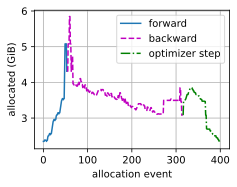

In [8]:
sign = {'alloc': 1, 'free_completed': -1}  # Other actions change nothing
sizes = torch.tensor([sign.get(e['action'], 0) * e['size'] for e in trace])
series = ((start + sizes.cumsum(0)) / 2**30).tolist()
bounds = [0, forward_end, backward_end, len(trace)]
phases = list(zip(bounds[:-1], bounds[1:]))
d2l.plot([list(range(a, b)) for a, b in phases],
         [series[a:b] for a, b in phases], 'allocation event',
         'allocated (GiB)', legend=['forward', 'backward', 'optimizer step'])

<!-- d2l:prose id=memory-precision-md-13 fw=pytorch -->

The trace starts at $12N$ (weights and two Adam moments), climbs linearly
across the blocks during the forward pass, spikes at the logits and the start
of the backward pass, and steps down as activations are freed and gradients
are allocated.

<!-- d2l:prose id=memory-precision-md-14 fw=all -->

## Mixed Precision

Mixed-precision training (that section) keeps master weights,
gradients, optimizer moments, normalizations, the residual stream, and the
loss in fp32 while running matrix multiplications and intermediate activations
in 16-bit floating point (bf16, which shares fp32's 8-bit exponent range and
needs no loss scaling, or fp16 with loss scaling, that section).

Because the two residual-stream inputs to a block's normalizations stay in
fp32 (4 bytes) while the remaining 18 of the ~$20d$ saved values per block
drop to bf16 (2 bytes), a block's saved activations shrink to roughly
$(2 \cdot 4 + 18 \cdot 2) / (20 \cdot 4) = 0.55$ of their fp32 size:

In [9]:
block16, head16 = bytes_per_token(config, bf16=True)
print(f'one block: {block16 / 2**10:.0f} KiB per token in bf16, '
      f'{block16 / block:.2f} of fp32')
print(f'embedding, output layer, and loss: {head16 / 2**10:.0f} KiB per token')

one block: 87 KiB per token in bf16, 0.58 of fp32
embedding, output layer, and loss: 306 KiB per token


<!-- d2l:prose id=memory-precision-md-15 fw=all -->

One block drops to $0.58\text{--}0.60$ of its fp32 activation bytes. However,
holding bf16 copies of the weights during the step increases fixed parameter
memory from $16N = 15.1$ GiB to $18N = 17.0$ GiB, leaving only 7.0 GiB for
activations. The activation savings and extra weight copies largely offset
each other, expanding the maximum token capacity on a 24 GiB card by only
15–25%.

The primary benefit of bf16 mixed precision is speed rather than capacity: on
the RTX 4090, bf16 tensor cores run at 165 TFLOP/s, twice the 82.6 TFLOP/s of
tf32 and fp32. To separate the effect of tensor cores (tf32 vs. scalar fp32)
from the effect of 16-bit operands (bf16 vs. tf32), we benchmark one SGD step
of a compute-bound three-layer MLP of width 8,192 on a batch of 2,048 examples
($1.1 \times 10^{12}$ FLOPs/step: roofline floor 13.3 ms at 82.6 TFLOP/s and
6.7 ms at 165 TFLOP/s, plus ~1.3 ms for the bandwidth-bound SGD update).

In [10]:
sizes = [(64 * 64, 8192), (8192, 8192), (8192, 10)]  # (inputs, outputs)
mlp = nn.Sequential(nn.Linear(*sizes[0], bias=False), nn.ReLU(),
                    nn.Linear(*sizes[1], bias=False), nn.ReLU(),
                    nn.Linear(*sizes[2], bias=False)).to(gpu)
for layer in mlp[::2]:  # Weights drawn from N(0, 0.02^2)
    nn.init.normal_(layer.weight, std=0.02)
X_mlp = torch.randn(2048, 64 * 64, device=gpu)
y_mlp = torch.randint(0, 10, (2048,), device=gpu)
opt = torch.optim.SGD(mlp.parameters(), lr=0.01)

def step(bf16):
    with torch.autocast(X_mlp.device.type, torch.bfloat16, enabled=bf16):
        l = F.cross_entropy(mlp(X_mlp), y_mlp)
    l.backward()
    opt.step()
    opt.zero_grad(set_to_none=True)

<!-- d2l:prose id=memory-precision-md-16 fw=all -->

Next, we count the exact multiply-accumulate operations (`macs`) and total
`flops` for the forward and backward matrix products of the MLP and define
`report` to benchmark each precision format in milliseconds and TFLOP/s:

In [11]:
# Two FLOPs per multiply-add, in the forward pass, the weight gradients, and
# the input gradients of every layer but the first
macs = sum(i * o for i, o in sizes)  # Per example and pass
flops = 2 * len(X_mlp) * (3 * macs - sizes[0][0] * sizes[0][1])
print(f'{flops:.2e} FLOPs per step')

def report(desc, f):
    """Print the time per call of f and the arithmetic rate it achieves."""
    t = d2l.Benchmark(f).time
    print(f'{desc}: {1000 * t:5.2f} ms, {flops / t / 1e12:3.0f} TFLOP/s')

1.10e+12 FLOPs per step


<!-- d2l:prose id=memory-precision-md-17 fw=all -->

We now run `report` across strict scalar `'fp32'`, tensor-core `'tf32'`, and
mixed-precision `'bf16'`:

In [12]:
torch.set_float32_matmul_precision('highest')  # True fp32
report('fp32', lambda: step(False))
torch.set_float32_matmul_precision('high')  # fp32 matmuls may use tf32
report('tf32', lambda: step(False))
report('bf16', lambda: step(True))

fp32: 23.15 ms,  48 TFLOP/s


tf32: 15.01 ms,  73 TFLOP/s
bf16:  9.68 ms, 114 TFLOP/s


<!-- d2l:prose id=memory-precision-md-18 fw=all -->

True fp32 on scalar units reaches ~60% of its 82.6 TFLOP/s peak because every
multiply-add and address calculation competes for instruction issue slots;
tf32 on the tensor cores reaches ~90% of the same peak, cutting step time by
a third without changing stored types. Moving from tf32 to bf16 speeds up the
step by another $1.5\text{--}1.75\times$ (close to the $6.7 + 1.3 = 8.0$ ms
floor plus update, since the fp32 SGD update and weight casts do not shrink).

## Activation Checkpointing

To multiply the number of tokens that fit on a card, a step must store fewer
activations. *Activation checkpointing* (that section,
[@Chen.Xu.Zhang.ea.2016]) saves only the input of each Transformer block
($d$ fp32 values, or $4d$ bytes per token) during the forward pass and
recomputes the block's internal activations one block at a time during the
backward pass. This trades one extra forward pass (~33% more compute, or $8N$
FLOPs/token instead of $6N$) for reducing peak per-token memory across $L$
blocks from $L a + a_\textrm{out} + \Delta$ to at most

$$
L \cdot 4d + a + a_\textrm{out} + \Delta,
$$

where $a$ is the single block currently being recomputed and $\Delta$ is the
excess of the measured peak over the count (that section).

In [13]:
M_gpu, d, L = 24 * 2**30, config['num_hiddens'], config['num_blks']
slope = (peaks[8192] - peaks[4096]) / 4096  # Growth per token, measured
excess = slope - (2 * block + head)  # Measured peak above the count
budgets = {  # Configuration: (fixed bytes, bytes per token at the peak)
    'fp32, count': (16 * N, L * block + head),
    'fp32, measured': (16 * N, L * block + head + excess),
    'bf16, measured': (18 * N, L * block16 + head16 + excess),
    'fp32, checkpointing': (16 * N, L * 4 * d + block + head + excess),
    'bf16, checkpointing': (18 * N, L * 4 * d + block16 + head16 + excess)}
for name, (fixed, per_token) in budgets.items():  # M(n) <= M_gpu
    print(f'{name:19s}: {per_token / 2**20:.2f} MiB per token, room for '
          f'{(M_gpu - fixed) / per_token:6,.0f} tokens')

fp32, count        : 2.83 MiB per token, room for  3,229 tokens
fp32, measured     : 3.22 MiB per token, room for  2,844 tokens
bf16, measured     : 2.21 MiB per token, room for  3,272 tokens
fp32, checkpointing: 0.88 MiB per token, room for 10,435 tokens
bf16, checkpointing: 0.91 MiB per token, room for  7,956 tokens


<!-- d2l:prose id=memory-precision-md-19 fw=all -->

With per-block checkpointing, the 18 blocks together store only
$18 \times 8 = 144$ KiB/token (less than the output layer and loss alone), raising
the token budget more than threefold (to 10,000–15,000 tokens). Notice that under checkpointing, bf16 actually fits slightly *fewer*
tokens than fp32 because the extra $2N$ bytes of bf16 weight copies outweigh
the activation savings on the single recomputed block. At that point, the
output logits and cross-entropy loss dominate per-token memory; computing the
output projection and loss in token chunks inside a checkpoint of its own
eliminates that bottleneck for only $2dV / (6N) \approx 3\%$ extra FLOPs
(Exercise 6).

Let us measure per-block checkpointing on a 4-block stack with two 1,024-token
sequences (which should store $5 \times 4d = 40$ KiB/token across the four
block inputs and final output):

In [14]:
blocks = d2l.GPT(**{**config, 'num_blks': 4}).to(gpu).blks
def stack(H, remat):
    for blk in blocks:
        H = checkpoint(blk, H, use_reentrant=False) if remat else blk(H)
    return H.square().mean()

d = config['num_hiddens']
H1, H2 = (torch.randn(b, 1024, d, device=gpu, requires_grad=True)
          for b in (1, 2))
for remat in (False, True):
    stored = (saved_bytes(stack, H2, remat)
              - saved_bytes(stack, H1, remat)) / 1024
    stack(H2, remat).backward()  # Warm-up; allocates the gradients
    peak = d2l.peak_memory(lambda: stack(H2, remat).backward())
    t = d2l.Benchmark(lambda: stack(H2, remat).backward()).time
    print(f'checkpointing={remat!s:5}: stores {stored / 2**10:4.0f} KiB per '
          f'token, peak {peak / 2**30:.2f} GiB, {1000 * t:.0f} ms per step')

checkpointing=False: stores  606 KiB per token, peak 1.25 GiB, 47 ms per step


checkpointing=True : stores   40 KiB per token, peak 0.42 GiB, 59 ms per step


<!-- d2l:prose id=memory-precision-md-20 fw=all -->

Checkpointing reduces the saved tensors to the exact 40 KiB/token predicted,
cuts peak activation memory substantially, and lengthens step time by ~25%
(within the 33% bound of one extra forward pass). Instead of recomputing an
entire block, *selective recomputation* [@Korthikanti.Casper.Lym.ea.2022]
saves the expensive matrix-multiplication outputs and recomputes only cheap
elementwise activations such as the SwiGLU gate product (Exercise
5).

## Gradient Accumulation

To reach a global batch $B_\textrm{global} = m \, B_\textrm{micro}$ of
hundreds of thousands of tokens without storing more activations, *gradient
accumulation* splits the global batch into $m$ sequential micro-batches,
accumulates their gradients (dividing each micro-batch mean loss by $m$), and
runs the optimizer once at the end.

While gradient accumulation performs the same arithmetic as a single large
batch, each micro-batch after the first reads the running gradient accumulator
and the new gradient and writes their sum ($12N$ bytes of memory traffic),
while the micro-batch itself performs $6Nn$ FLOPs on $n$ tokens. Relative to
peak compute time, this accumulator traffic costs

$$
\frac{12N / \beta}{6Nn / P} = \frac{2 I^*}{n},
$$

where $I^* = P/\beta$ is the ridge point (that section). For tf32
($I^* = 82$) and micro-batches of $n = 1{,}024$ tokens, that overhead is ~16%
on each of the $m - 1$ accumulating micro-batches; at $n = 4{,}096$ tokens, it
drops to 4%.

We verify both numerical equivalence and memory/time overhead on our 2-block
GPT for 4,096 tokens processed as 1 batch versus $m = 4$ micro-batches of
1,024 tokens:

In [15]:
X = torch.randint(0, V, (4, 1024), device=gpu)  # 4,096 tokens per step

def accumulate(model, X, m):
    """Gradient of the loss on X in .grad, accumulated over m micro-batches."""
    model.zero_grad(set_to_none=True)
    for Xb in X.chunk(m):
        (gpt_loss(model, Xb) / m).backward()  # / m: the loss averages

accumulate(model, X, 1)
full = [p.grad.clone() for p in model.parameters()]  # One-batch gradient
for m in (1, 4):
    model.zero_grad(set_to_none=True)
    peak = d2l.peak_memory(accumulate, model, X, m)
    assert max((p.grad - g).norm() / g.norm()
               for p, g in zip(model.parameters(), full)) < 1e-2
    f = lambda: accumulate(model, X, m)
    times = 1000 * np.array([d2l.Benchmark(f).time for _ in range(5)])  # ms
    kernels = d2l.kernel_times(f)        # Device ms per step, per kernel
    busy = sum(kernels.values())
    products = sum(ms for name, ms in kernels.items()
                   if re.search(d2l.PRODUCT_KERNELS, name, re.I))
    print(f'{m} x {4096 // m:4d} tokens: peak {peak / 2**30:.2f} GiB above '
          f'the weights, {np.median(times):.0f} ms per step '
          f'({times.min():.0f} to {times.max():.0f}), device busy '
          f'{busy:.0f} ms\n{"":16s}matrix products {products:.0f} ms, '
          f'other kernels {busy - products:.0f} ms')

1 x 4096 tokens: peak 3.53 GiB above the weights, 83 ms per step (83 to 83), device busy 83 ms
                matrix products 69 ms, other kernels 13 ms


4 x 1024 tokens: peak 1.92 GiB above the weights, 99 ms per step (99 to 99), device busy 99 ms
                matrix products 74 ms, other kernels 25 ms


<!-- d2l:prose id=memory-precision-md-21 fw=all -->

Peak memory above the weights drops by roughly half (since the $4N = 0.77$ GiB
of persistent gradients remain allocated across micro-batches while activation
memory drops fourfold), and step time increases by 10–20% due to accumulator
additions and slightly lower tensor-core efficiency on smaller micro-batches.
The optimal micro-batch is therefore always the largest one that fits in
memory.

## Choosing a Memory Technique

the table summarizes the memory techniques by the symptom
that calls for each.

<!-- tbl-caption:Memory techniques by symptom, with their effect on the equation and their cost. -->

| symptom | technique | effect on memory | cost |
|---|---|---|---|
| matrix products dominate step time | bf16 mixed precision | activations $\times 0.6$, fixed state $+2N$ for weight copies | 8-bit significand rounding (fp16 also needs loss scaling) |
| a useful micro-batch does not fit | activation checkpointing | stored activations per block from $a$ to $4d$ bytes/token | one extra forward pass (~25–33% more time) |
| output layer and loss dominate | chunked cross-entropy loss | $a_\textrm{out}$ and $\Delta$ for one token chunk at a time | one extra pass through the output projection (~3% FLOPs) |
| global batch exceeds micro-batch capacity | gradient accumulation | none; global batch grows $m$-fold | accumulator traffic $2I^*/n$; repeated weight reads per micro-batch |
| $16N$ parameter state alone fills the card | sharding weights, gradients, and optimizer state (that section) | $16N/k$ on each of $k$ GPUs | inter-GPU collective communication |

For our 1B-parameter GPT on a single RTX 4090, bf16 mixed precision fits two
or three sequences of 1,024 tokens without checkpointing, and accumulating 256
micro-batches reaches a global batch of 524,288 tokens. At $6N$ FLOPs/token,
however, one global step requires $3.2 \times 10^{15}$ FLOPs—at least 19 s per
step on one card, or more than three weeks for 100,000 steps (52B tokens). A
single GPU can hold a step of our GPT, but finishing the run requires multiple
GPUs (that section).

## Summary

Training step memory splits into a fixed parameter term ($16N$ bytes for fp32
Adam, $18N$ with bf16 weight copies) and a per-token activation term. By three
differentiation rules (linear layers keep inputs, elementwise functions keep
inputs or outputs, products keep both factors), a fused SwiGLU Transformer
block stores ~$20d$ values per token, and the cross-entropy loss stores $V$
log-probabilities; the peak can exceed this count by backward temporaries at
the loss, which is why we measure it. Mixed precision accelerates
matrix products on tensor cores while leaving total memory capacity nearly
unchanged; activation checkpointing stores only block inputs ($4d$ bytes/token)
at the cost of ~25% extra time; and gradient accumulation builds large global
batches from micro-batches that fit, adding an accumulator traffic fraction of
$2I^*/n$.

## Exercises

1. **Where the peak lands.** the figure places the peak
   of a training step at the start of the backward pass. Consider a stack of
   $n$ identical layers where each layer's parameters occupy $w$ bytes and
   its forward pass stores $a$ bytes of activations. Assume no gradients
   exist when the backward pass starts, and each layer's backward pass frees
   its $a$ bytes of activations and allocates $w$ bytes of parameter
   gradients.
    1. Write the bytes held by activations and gradients after the backward
       pass has processed $j$ of the $n$ layers. Show that the peak lies at
       the start of the backward pass when $a > w$ and at its end when
       $a < w$.
    1. A block of our GPT holds ~$12d^2$ parameters and stores ~$20d$ fp32
       values per token. Above what token count per step does the peak lie at
       the start of the backward pass?
    1. Under gradient accumulation over $m$ micro-batches, the gradients of
       the first micro-batch remain allocated while later micro-batches run.
       Find the peak with accumulation and the values of $m$ for which
       accumulation lowers the peak below a single full-batch step.

<!-- d2l:prose id=memory-precision-md-22 fw=pytorch -->

2. [code] **Optimizer-step memory.** Build the two-block GPT of
   that section with three `torch.optim.Adam` configurations:
   `foreach=False`, the default, and `fused=True`.
    1. Run two steps with each optimizer. On the second step, measure the
       peak extra bytes allocated during `opt.step()` in units of the gradient
       size $4N$.
    1. Explain the three measurements from how each implementation updates
       parameter tensors (one tensor at a time, batched multi-tensor
       elementwise ops, or a single fused kernel). When can the optimizer step
       set the overall peak of a training step?

<!-- d2l:prose id=memory-precision-md-23 fw=all -->

3. **Clipping under accumulation.** Gradient clipping to norm $\tau$
   replaces $\mathbf{g}$ by $\mathbf{g} \min(1, \tau / \|\mathbf{g}\|)$. Let
   $\mathbf{g}_1, \ldots, \mathbf{g}_m$ be micro-batch gradients scaled by
   $1/m$ so their sum $\mathbf{g}$ is the global-batch gradient.
    1. If a loop clips each $\mathbf{g}_i$ before adding it to the
       accumulator, what is the maximum norm the accumulated gradient can
       reach, and when does per-micro-batch clipping match global clipping?
    1. Under fp16 loss scaling with factor $S$, the accumulator holds
       $S \mathbf{g}$ after the final micro-batch. In what order must the loop
       unscale by $S$, clip, and step? What goes wrong if $S$ changes between
       micro-batches?

<!-- d2l:prose id=memory-precision-md-24 fw=pytorch -->

4. [code] **fp16 gradient window.** ● The 5-bit exponent of fp16 gives it
   normal numbers from $2^{-14}$ to 65,504 and subnormals down to $2^{-24}$.
   Loss scaling [@Micikevicius.Narang.Alben.ea.2018] multiplies the loss
   by $S$ before `backward()` and divides gradients by $S$ afterward. Using
   `mlp`, `X_mlp`, and `y_mlp` from that section with true fp32
   reference gradients:
    1. Plot a histogram of $\log_2 |g|$ over all nonzero reference gradient
       entries and find the scale factors $S$ that place 99.9% of scaled
       entries $Sg$ inside the normal range of fp16.
    1. For $S = 2^0, 2^2, \ldots, 2^{24}$, compute gradients under
       `torch.autocast('cuda', dtype=torch.float16)`, unscale by $S$, and plot
       the relative error $\|\hat{\mathbf{g}} - \mathbf{g}\| / \|\mathbf{g}\|$.
       Repeat with `torch.bfloat16`. In which window of $S$ is fp16 more
       accurate than bf16, and why?
    1. How does the valid window of $S$ shift if the batch size grows from
       2,048 to 32,768?

<!-- d2l:prose id=memory-precision-md-25 fw=pytorch -->

5. [code] **Selective recomputation.** ● Per-block checkpointing stores only
   each block's input. Passing
   `torch.utils.checkpoint.create_selective_checkpoint_contexts` via the
   `context_fn` argument of `checkpoint` caches the outputs of selected ops
   (such as `torch.ops.aten.mm.default`) and recomputes the rest.
    1. For one block of our GPT, list the saved tensors and the recomputed
       matrix products under three policies: full per-block checkpointing,
       caching every `mm` output, and caching all `mm` outputs except the FFN
       gate and up-projection.
    1. Implement the latter two policies on the 4-block stack of
       that section and compare saved bytes/token, peak
       memory, and step time.

<!-- d2l:prose id=memory-precision-md-26 fw=all -->

6. [extended] **The loss in chunks.** ●● Under per-block checkpointing, the
   output layer and cross-entropy loss of our GPT store more memory per token
   than all 18 blocks combined because the loss materializes $V = 50{,}257$
   log-probabilities and their gradients per token.
    1. Write the output projection and cross-entropy loss to process tokens in
       chunks of size $n_c = 1024$, wrapping each chunk in a checkpoint so
       that logits and log-probabilities exist for only one chunk at a time.
       Verify that the loss and gradients match the unchunked version.
    1. Predict the maximum micro-batch size of our 18-block GPT on a 24 GiB
       card with per-block checkpointing and the chunked loss, and measure the
       per-token memory slope and step time on the 2-block GPT.

[Discussions](https://d2l.discourse.group/t/36790)